In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
file_path = "C:/Users/RSCH/Desktop/DWD/Final project/Retail-Intelligence-Platform/datasets/amez_dataset_cleaned.xlsx"

data = pd.read_excel(
    file_path,
    sheet_name="Overall_Transactions"
)

data.head()

,InvoiceID,InvoiceDate,CustomerID,ProductID,ProductName,Category,SubCategory,Quantity,UnitPrice,Discount,TotalAmount,StockQuantity,StoreID,StoreName
0,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,8e4669ab-db13-4000-0bd7-f03200008e46,Merino Wool Minimalist Crewneck Knitwear,Fashion & Apparel,Men's Fashion,1,11500.0,2000,9500.0,75,9abc0803-cfe9-4000-0a98-919a00009abc,Luxe Apparel Studio
1,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,Beauty & Wellness,Skincare Essentials,2,6800.0,2000,11600.0,115,9fbc0fe2-cae9-4000-0ac8-967b00009fbc,Glow Naturals Cosmetics
2,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,7ec257a3-2b97-4000-04df-ce3a00007ec2,Velocity Pro Carbon Running Sneakers,Fashion & Apparel,Footwear,2,17500.0,4000,31000.0,95,a0bc1175-f5e9-4000-0938-88ec0000a0bc,Velocity Athletic Gear
3,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,81c25c5c-d497-4000-0b2f-c5c5000081c2,Ergonomic Breathable Mesh Desk Chair,Home & Living,Modern Furniture,1,28000.0,4000,24000.0,50,99bc0670-cce9-4000-0aa8-9fe9000099bc,Nordic Living Essentials
4,INV-2026-1001,2026-01-01,64d75846-3182-4000-057e-c1df000064d,93c93477-c69c-4000-0a0f-adee000093c9,Bio-Peptide Restorative Night Crème,Beauty & Wellness,Skincare Essentials,1,6800.0,1000,5800.0,115,9fbc0fe2-cae9-4000-0ac8-967b00009fbc,Glow Naturals Cosmetics


In [3]:
print("Rows:", len(data))
print("Columns:", len(data.columns))

Rows: 11992
Columns: 14


In [4]:
print(data.columns.tolist())

['InvoiceID', 'InvoiceDate', 'CustomerID', 'ProductID', 'ProductName', 'Category', 'SubCategory', 'Quantity', 'UnitPrice', 'Discount', 'TotalAmount', 'StockQuantity', 'StoreID', 'StoreName']


In [5]:
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])

print(data["InvoiceDate"].dtype)

datetime64[us]


In [6]:
print("Unique customers:", data["CustomerID"].nunique())
print("Missing CustomerID:", data["CustomerID"].isnull().sum())

Unique customers: 2464
Missing CustomerID: 0


In [7]:
print("Unique invoices:", data["InvoiceID"].nunique())
print("Missing InvoiceID:", data["InvoiceID"].isnull().sum())

Unique invoices: 2570
Missing InvoiceID: 0


In [8]:
print(data["TotalAmount"].describe())

count     11992.000000
mean      51160.368662
std       59325.569216
min        -422.000000
25%       16272.000000
50%       32796.000000
75%       63660.500000
max      897153.000000
Name: TotalAmount, dtype: float64


In [9]:
reference_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Latest transaction date:", data["InvoiceDate"].max())
print("RFM reference date:", reference_date)

Latest transaction date: 2026-08-15 01:45:53
RFM reference date: 2026-08-16 01:45:53


In [11]:
last_purchase = data.groupby("CustomerID")["InvoiceDate"].max().reset_index()

last_purchase.head()

,CustomerID,InvoiceDate
0,0025d7a1-81d7-4240-8807-4aed48f88cde,2026-03-15 07:39:44
1,00381394-0d27-43e1-aa0c-2105ea482b2b,2026-02-12 18:11:26
2,003c8473-1b85-445f-bcfb-948e6c9f8451,2026-05-07 06:27:27
3,004d5aa3-b784-4619-8e18-0411b8f90404,2026-06-06 19:28:21
4,0089210b-880d-4835-b385-14486458934b,2026-05-19 11:31:08


In [12]:
last_purchase["Recency"] = (
    reference_date - last_purchase["InvoiceDate"]
).dt.days

last_purchase.head()

,CustomerID,InvoiceDate,Recency
0,0025d7a1-81d7-4240-8807-4aed48f88cde,2026-03-15 07:39:44,153
1,00381394-0d27-43e1-aa0c-2105ea482b2b,2026-02-12 18:11:26,184
2,003c8473-1b85-445f-bcfb-948e6c9f8451,2026-05-07 06:27:27,100
3,004d5aa3-b784-4619-8e18-0411b8f90404,2026-06-06 19:28:21,70
4,0089210b-880d-4835-b385-14486458934b,2026-05-19 11:31:08,88


In [13]:
frequency = data.groupby("CustomerID")["InvoiceID"].nunique().reset_index()

frequency.columns = ["CustomerID", "Frequency"]

frequency.head()

,CustomerID,Frequency
0,0025d7a1-81d7-4240-8807-4aed48f88cde,1
1,00381394-0d27-43e1-aa0c-2105ea482b2b,1
2,003c8473-1b85-445f-bcfb-948e6c9f8451,1
3,004d5aa3-b784-4619-8e18-0411b8f90404,1
4,0089210b-880d-4835-b385-14486458934b,1


In [14]:
monetary = data.groupby("CustomerID")["TotalAmount"].sum().reset_index()

monetary.columns = ["CustomerID", "Monetary"]

monetary.head()

,CustomerID,Monetary
0,0025d7a1-81d7-4240-8807-4aed48f88cde,258142.0
1,00381394-0d27-43e1-aa0c-2105ea482b2b,396249.0
2,003c8473-1b85-445f-bcfb-948e6c9f8451,375593.0
3,004d5aa3-b784-4619-8e18-0411b8f90404,162866.0
4,0089210b-880d-4835-b385-14486458934b,278088.0


In [15]:
monetary = data.groupby("CustomerID")["TotalAmount"].sum().reset_index()

monetary.columns = ["CustomerID", "Monetary"]

monetary.head()


,CustomerID,Monetary
0,0025d7a1-81d7-4240-8807-4aed48f88cde,258142.0
1,00381394-0d27-43e1-aa0c-2105ea482b2b,396249.0
2,003c8473-1b85-445f-bcfb-948e6c9f8451,375593.0
3,004d5aa3-b784-4619-8e18-0411b8f90404,162866.0
4,0089210b-880d-4835-b385-14486458934b,278088.0


In [16]:
rfm = last_purchase[["CustomerID", "Recency"]].merge(
    frequency,
    on="CustomerID"
)

rfm = rfm.merge(
    monetary,
    on="CustomerID"
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0


In [17]:
print("RFM rows:", len(rfm))
print("RFM columns:", len(rfm.columns))

rfm.head()

RFM rows: 2464
RFM columns: 4


,CustomerID,Recency,Frequency,Monetary
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0


In [18]:
print(rfm.isnull().sum())

CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64


In [19]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,2464.000000,2464.000000,2.464000e+03
mean,108.471591,1.043831,2.489915e+05
std,62.679582,0.557409,1.997596e+05
min,1.000000,1.000000,2.720000e+03
25%,54.000000,1.000000,1.430055e+05
50%,108.000000,1.000000,2.221525e+05
75%,162.000000,1.000000,3.112840e+05
max,227.000000,12.000000,3.612815e+06


In [20]:
rfm.sort_values(
    "Monetary",
    ascending=False
).head(10)

,CustomerID,Recency,Frequency,Monetary
958,66d75b6c-3382-4000-055e-c2f5000066d7,213,8,3612815.0
947,65d759d9-3082-4000-056e-c040000065d7,216,10,3259680.0
1744,b109ff52-e45c-4000-0823-66cb0000b109,213,8,3121845.0
1691,ad09f906-f85c-4000-09e3-609f0000ad09,213,12,2895716.0
1674,ac09f773-f95c-4000-09f3-6eea0000ac09,213,9,2765209.0
1087,71d76cbd-2482-4000-042e-f524000071d7,214,7,1919564.0
1079,70d76b2a-2582-4000-043e-f2b3000070d7,214,7,1828695.0
910,62d75520-3782-4000-051e-ccb9000062d7,215,10,1452394.0
991,68d75e92-3d82-4000-05be-c70b000068d7,214,9,1369640.0
921,63d756b3-3682-4000-050e-cf2a000063d7,213,7,1320362.0


In [21]:
rfm.sort_values(
    "Recency",
    ascending=True
).head(10)

,CustomerID,Recency,Frequency,Monetary
2444,fdc068fd-8c17-4ede-a4f2-1dbb,1,1,77667.0
1030,6c641de7-3c53-42b1-88a5-7702bc5e,1,1,81150.0
1527,9e9b9dae-afab-40d6-8cdc-5666cfadf0d1,1,1,173828.0
33,03d0f-38ea-03-8f0e-2b3c96bd7bf4,1,1,56856.0
34,03d0f232-38ea-4503-8f0e-2b3c96bd7bf4,1,2,250374.0
2445,fdc0fd-8c17-4ede-a4f2-1dbb74163,1,1,422666.0
423,2dfc43a5-0f7c-4343-9d75-0db96cd6f27c,2,1,666051.0
1059,6efeca8a-9006-4052-b144-d83f07e0dd5c,2,1,128952.0
2366,f5ab9b04-afc6-4831-a482-27a0697188e8,2,1,127494.0
1505,9c8aead8-e46f-46e8-957d-edc9419983,2,1,276651.0


In [22]:
rfm.sort_values(
    "Frequency",
    ascending=False
).head(10)

,CustomerID,Recency,Frequency,Monetary
1691,ad09f906-f85c-4000-09e3-609f0000ad09,213,12,2895716.0
947,65d759d9-3082-4000-056e-c040000065d7,216,10,3259680.0
910,62d75520-3782-4000-051e-ccb9000062d7,215,10,1452394.0
991,68d75e92-3d82-4000-05be-c70b000068d7,214,9,1369640.0
1674,ac09f773-f95c-4000-09f3-6eea0000ac09,213,9,2765209.0
958,66d75b6c-3382-4000-055e-c2f5000066d7,213,8,3612815.0
1744,b109ff52-e45c-4000-0823-66cb0000b109,213,8,3121845.0
1087,71d76cbd-2482-4000-042e-f524000071d7,214,7,1919564.0
1079,70d76b2a-2582-4000-043e-f2b3000070d7,214,7,1828695.0
921,63d756b3-3682-4000-050e-cf2a000063d7,213,7,1320362.0


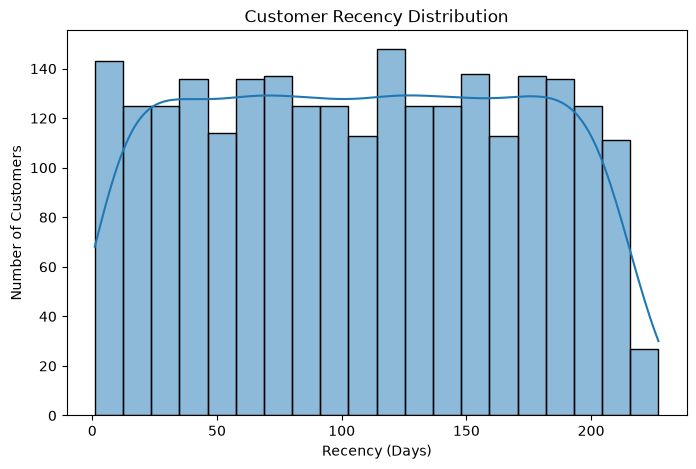

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(
    rfm["Recency"],
    bins=20,
    kde=True
)

plt.title("Customer Recency Distribution")
plt.xlabel("Recency (Days)")
plt.ylabel("Number of Customers")

plt.show()

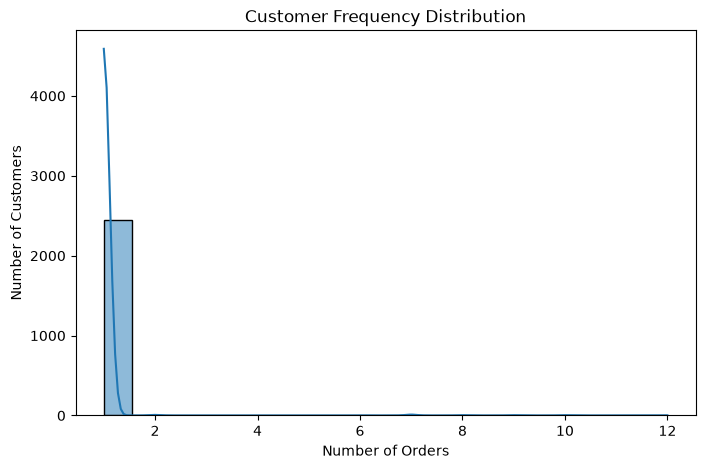

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    rfm["Frequency"],
    bins=20,
    kde=True
)

plt.title("Customer Frequency Distribution")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.show()

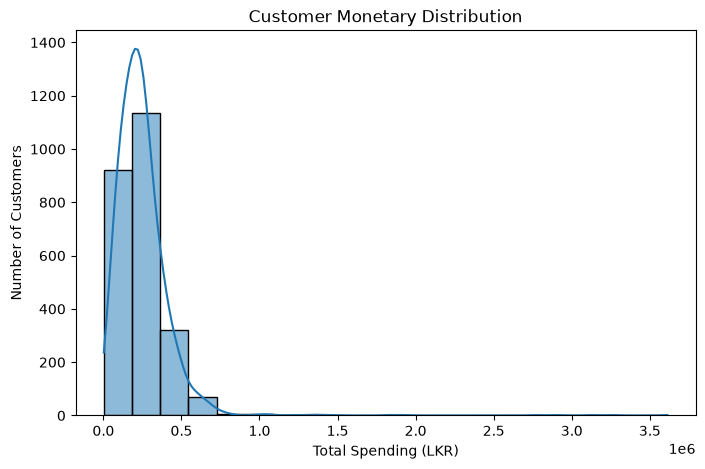

In [25]:
plt.figure(figsize=(8, 5))

sns.histplot(
    rfm["Monetary"],
    bins=20,
    kde=True
)

plt.title("Customer Monetary Distribution")
plt.xlabel("Total Spending (LKR)")
plt.ylabel("Number of Customers")

plt.show()

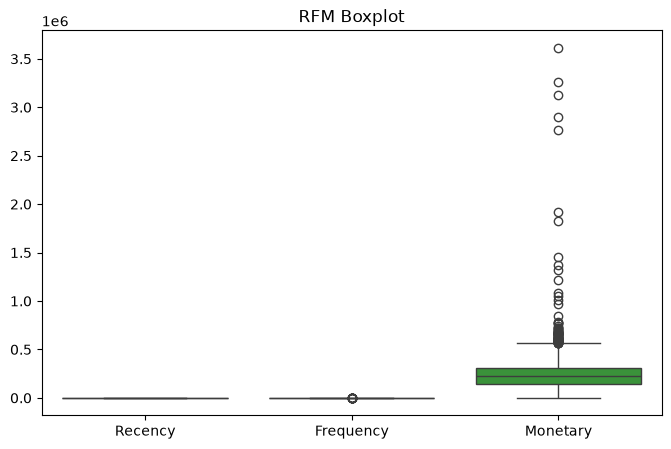

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=rfm[
        ["Recency", "Frequency", "Monetary"]
    ]
)

plt.title("RFM Boxplot")

plt.show()

In [27]:
rfm_correlation = rfm[
    ["Recency", "Frequency", "Monetary"]
].corr()

rfm_correlation

,Recency,Frequency,Monetary
Recency,1.000000,0.129968,0.151448
Frequency,0.129968,1.000000,0.663381
Monetary,0.151448,0.663381,1.000000


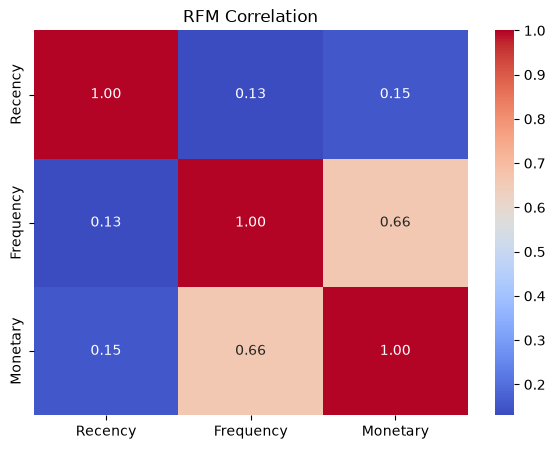

In [28]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    rfm_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("RFM Correlation")

plt.show()

In [29]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

In [30]:
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [31]:
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [32]:
rfm["R_Score"] = rfm["R_Score"].astype(int)
rfm["F_Score"] = rfm["F_Score"].astype(int)
rfm["M_Score"] = rfm["M_Score"].astype(int)

In [33]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,2,1,4,214
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,1,5,115
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,3,1,5,315
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,4,1,2,412
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,3,1,4,314


In [34]:
rfm["RFM_Total"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,2,1,4,214,7
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,1,5,115,7
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,3,1,5,315,9
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,4,1,2,412,7
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,3,1,4,314,8


In [35]:
rfm[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "R_Score",
        "F_Score",
        "M_Score",
        "RFM_Score",
        "RFM_Total"
    ]
].head(20)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,2,1,4,214,7
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,1,5,115,7
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,3,1,5,315,9
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,4,1,2,412,7
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,3,1,4,314,8
5,00d26b82-3d0d-49c7-9d15-e0dab6739ddd,154,1,447464.0,2,1,5,215,8
6,00e77c94-b376-4239-8ee0-a6b783d2ac94,96,1,111612.0,3,1,1,311,5
7,0100f230-e005-4271-8ce6-3c30d088047d,36,1,471141.0,5,1,5,515,11
8,012de2cf-81ef-4b94-812f-7b1e7739b099,6,1,91173.0,5,1,1,511,7
9,0130243b-f72a-4a4d-9481-2a1ad6bb3c36,70,1,316870.0,4,1,4,414,9


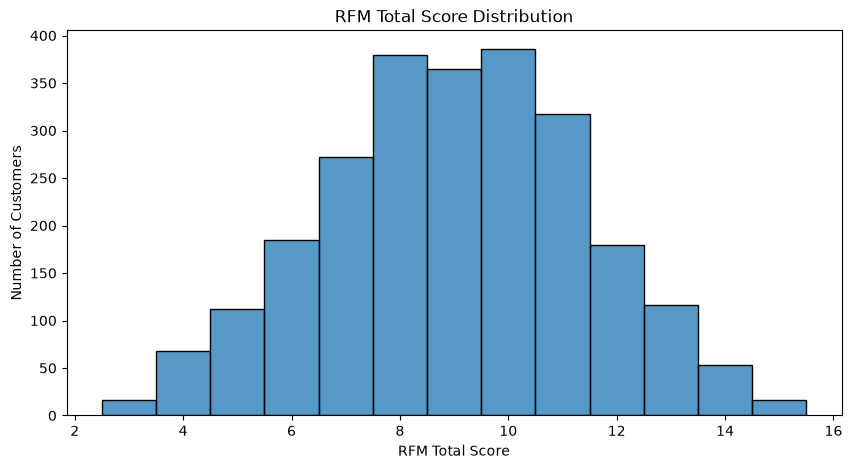

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    rfm["RFM_Total"],
    discrete=True
)

plt.title("RFM Total Score Distribution")
plt.xlabel("RFM Total Score")
plt.ylabel("Number of Customers")

plt.show()

In [37]:
high_value_customers = rfm[
    rfm["RFM_Total"] >= 12
].sort_values(
    "RFM_Total",
    ascending=False
)

high_value_customers.head(20)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
2440,fd587eec-48b7-41ea-bb9c-2fd5af3c2e71,24,1,610150.0,5,5,5,555,15
2377,f6a3f2ac-75ba-4cd6-bf64-3a98fc4cf274,11,1,433391.0,5,5,5,555,15
2419,faf78943-aafe-4f59-9f93-2f27e2d97a97,28,1,498696.0,5,5,5,555,15
2334,f2a0524f-c113-47b9-ab3a-5ede21f87e8c,28,1,414949.0,5,5,5,555,15
2398,f8e3a9c3-0bb3-4cb0-bf7a-445b1efa500c,8,1,363146.0,5,5,5,555,15
2173,e05298ad-d5de-4422-a0ad-6eb9dd6d41fc,19,1,403878.0,5,5,5,555,15
2168,df9ccc74-4365-422f-8d01-8fc1f847bb9d,36,1,603231.0,5,5,5,555,15
2262,ea5f36c3-ed6a-4701-bb9e-d91ddbd331a8,31,1,361981.0,5,5,5,555,15
2245,e8800229-e5f1-497a-9ee3-80b188a33008,38,1,382904.0,5,5,5,555,15
2136,dd0021a6-dab4-4933-9dc9-7724322a68a1,30,1,368843.0,5,5,5,555,15


In [38]:
def rfm_segment(row):

    if row["RFM_Total"] >= 13:
        return "High Value"

    elif row["RFM_Total"] >= 10:
        return "Loyal"

    elif row["RFM_Total"] >= 7:
        return "Potential"

    else:
        return "At Risk"


rfm["RFM_Segment"] = rfm.apply(
    rfm_segment,
    axis=1
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,RFM_Segment
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,2,1,4,214,7,Potential
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,1,5,115,7,Potential
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,3,1,5,315,9,Potential
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,4,1,2,412,7,Potential
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,3,1,4,314,8,Potential


In [39]:
rfm["RFM_Segment"].value_counts()

RFM_Segment
Potential     1016
Loyal          882
At Risk        381
High Value     185
Name: count, dtype: int64

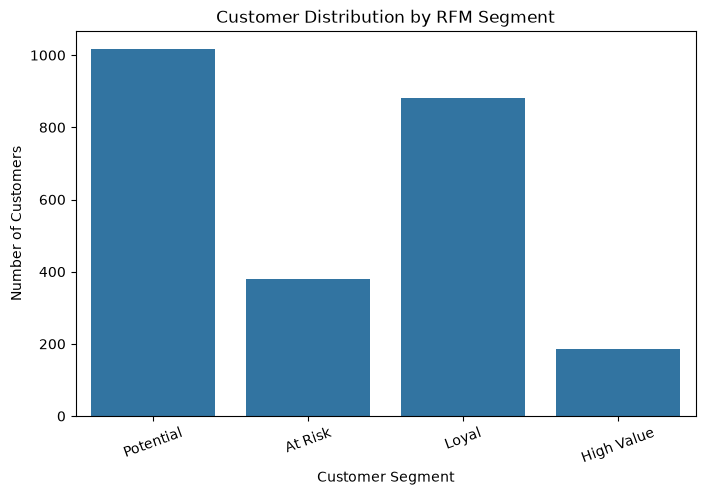

In [40]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="RFM_Segment"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

In [41]:
rfm.groupby("RFM_Segment").agg(
    Customers=("CustomerID", "count"),
    AverageRecency=("Recency", "mean"),
    AverageFrequency=("Frequency", "mean"),
    AverageMonetary=("Monetary", "mean")
).round(2)

,Customers,AverageRecency,AverageFrequency,AverageMonetary
RFM_Segment,,,,
At Risk,381,165.51,1.00,139188.15
High Value,185,49.07,1.01,358035.05
Loyal,882,86.14,1.12,310026.88
Potential,1016,117.29,1.00,217327.03


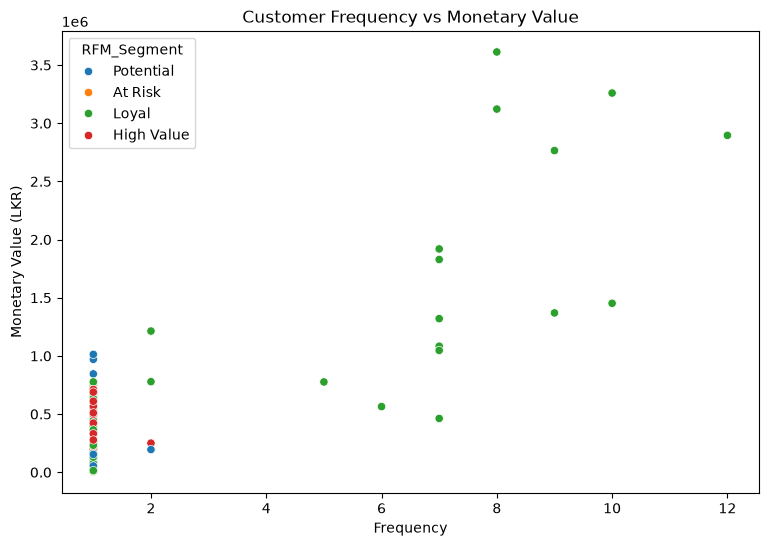

In [42]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="RFM_Segment"
)

plt.title("Customer Frequency vs Monetary Value")
plt.xlabel("Frequency")
plt.ylabel("Monetary Value (LKR)")

plt.show()

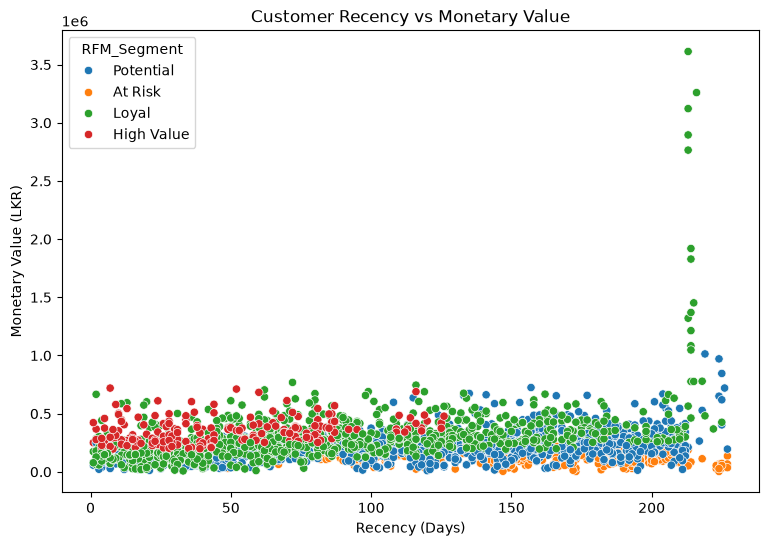

In [43]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="RFM_Segment"
)

plt.title("Customer Recency vs Monetary Value")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (LKR)")

plt.show()

In [44]:
rfm_for_clustering = rfm[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary"
    ]
].copy()

rfm_for_clustering.head()

,CustomerID,Recency,Frequency,Monetary
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0


In [45]:
rfm_file = "C:/Users/RSCH/Desktop/DWD/Final project/Retail-Intelligence-Platform/datasets/customer_rfm.xlsx"

rfm.to_excel(
    rfm_file,
    sheet_name="RFM_Analysis",
    index=False
)

print("RFM analysis saved successfully.")

RFM analysis saved successfully.


In [46]:
print("========== RFM ANALYSIS ==========")

print("Customers:", rfm["CustomerID"].nunique())

print(
    "Average Recency:",
    round(rfm["Recency"].mean(), 2)
)

print(
    "Average Frequency:",
    round(rfm["Frequency"].mean(), 2)
)

print(
    "Average Monetary:",
    round(rfm["Monetary"].mean(), 2)
)

print(
    "RFM records:",
    len(rfm)
)

print(
    "Missing values:",
    rfm.isnull().sum().sum()
)

print("==================================")

========== RFM ANALYSIS ==========
Customers: 2464
Average Recency: 108.47
Average Frequency: 1.04
Average Monetary: 248991.53
RFM records: 2464
Missing values: 0
